# Scan inspection: form error, deviation, regions and colour maps

A 3-D scan is measured against what it should be (roadmap §7.1.3 and §7.4): `fit_primitives` reports the **form error and extremes** of each fitted feature, `deviation` measures every scan point against a nominal surface or a fitted primitive and returns the statistics an inspection report carries, `deviation_regions` turns the map into the connected regions of **excess and missing material**, and `colorize` / `exaggerate` make the map visible in tools that show colours but not fields. See `doc/deviation.md`, `doc/colorize.md` and `doc/fit_primitives.md`.

The "scan" here is synthetic: a nominal plate with a bump and a dent, sampled with noise, so the numbers can be checked against what was put in.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None

WORK = tempfile.mkdtemp()


def render(panels, title, size=(1500, 520), cmap='coolwarm', clim=None, rgb=False):
    """PyVista renders of (mesh, scalar or None, subtitle) panels, embedded
    through matplotlib; a matplotlib scatter when GL is unavailable."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, scalar, sub) in enumerate(panels):
            pl.subplot(0, i)
            path = os.path.join(WORK, f'view{i}.vtu')
            mp.write(path, mesh)
            grid = pv.read(path)
            if rgb and 'red' in grid.array_names:
                colours = np.stack([grid['red'], grid['green'], grid['blue']], axis=1)
                pl.add_mesh(grid, scalars=colours, rgb=True, show_edges=False)
            elif scalar is not None and scalar in grid.array_names:
                pl.add_mesh(grid, scalars=scalar, cmap=cmap, clim=clim, show_edges=False,
                            scalar_bar_args={'title': scalar})
            else:
                pl.add_mesh(grid, color='#90caf9', show_edges=True, edge_color='#1f4e79',
                            line_width=0.3)
            pl.add_text(sub, font_size=10)
            pl.camera_position = 'iso'
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 5.2))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig = plt.figure(figsize=(15, 4.5))
        for i, (mesh, scalar, sub) in enumerate(panels):
            ax = fig.add_subplot(1, len(panels), i + 1, projection='3d')
            p = np.asarray(mesh.points)
            c = mesh.point_data[scalar] if scalar in mesh.point_data else p[:, 2]
            ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1, c=c, cmap=cmap)
            ax.set_title(sub)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

## Form error and extremes of fitted features

`fit_primitives` now reports, per patch, the peak-to-peak **form error** (flatness, cylindricity, sphericity under the least-squares reference), a sphere's or cylinder's smallest and largest **diameter**, a cylinder's or cone's **axial length** and **arc span**, and a plane's two in-plane **extents**. A half cylinder reads an arc of 180 degrees; a bore with a 0.01 step reads both diameters.

In [2]:
def half_cylinder(r=1.5, h=2.0, n=24, m=4):
    pts = [[r * np.cos(np.pi * k / n), r * np.sin(np.pi * k / n), h * i / m]
           for i in range(m + 1) for k in range(n + 1)]
    quads = [[i * (n + 1) + k, i * (n + 1) + k + 1, (i + 1) * (n + 1) + k + 1, (i + 1) * (n + 1) + k]
             for i in range(m) for k in range(n)]
    return mp.Mesh(np.array(pts, float), [('quad', np.array(quads))])


rng = np.random.default_rng(7)
shell = half_cylinder()
shell.points = np.asarray(shell.points) + rng.normal(0, 2e-4, np.shape(shell.points))
fitted = mp.fit_primitives(shell, patch_data='', tolerance=5e-3)
fd = fitted.field_data
for key in ('fit:patch_type', 'fit:patch_form_error', 'fit:patch_diameter_min',
            'fit:patch_diameter_max', 'fit:patch_length', 'fit:patch_arc'):
    print(f'{key:24s} {np.ravel(fd[key])[0]:.6g}')

fit:patch_type           3
fit:patch_form_error     0.00115242
fit:patch_diameter_min   2.99867
fit:patch_diameter_max   3.00098
fit:patch_length         2.00092
fit:patch_arc            180.005


## A nominal plate and its scan

The nominal is a 40 x 20 x 2 plate. The scan is its top face, densely sampled, with a 0.3 high bump, a 0.2 deep dent and 0.005 of noise. `deviation` measures every scan point against the nominal: positive outside it (excess material), negative inside (missing material). The **far-side rule** (`max_normal_angle`, 90 degrees by default) keeps each point on the face it was scanned from.

In [3]:
nominal = mp.box_surface(size=(40.0, 20.0, 2.0))
nx, ny = 160, 80
xs, ys = np.meshgrid(np.linspace(0, 40, nx + 1), np.linspace(0, 20, ny + 1))
bump = 0.3 * np.exp(-((xs - 12) ** 2 + (ys - 10) ** 2) / 8.0)
dent = -0.2 * np.exp(-((xs - 28) ** 2 + (ys - 8) ** 2) / 6.0)
zs = 2.0 + bump + dent + rng.normal(0, 0.005, xs.shape)
pts = np.column_stack([xs.ravel(), ys.ravel(), zs.ravel()])
quads = [[j * (nx + 1) + i, j * (nx + 1) + i + 1, (j + 1) * (nx + 1) + i + 1, (j + 1) * (nx + 1) + i]
         for j in range(ny) for i in range(nx)]
scan = mp.Mesh(pts, [('quad', np.array(quads))])

measured, report = mp.deviation(scan, nominal, tolerance=0.05, bins=24, return_report=True)
for key in ('num_measured', 'min', 'max', 'mean', 'rms', 'sigma', 'share_within', 'suggested_range'):
    print(f'{key:16s} {report[key]:.6g}')
print('percentiles     ', {k: round(v, 4) for k, v in report['percentiles'].items()})

num_measured     13041
min              -0.200678
max              0.304618
mean             0.00466388
rms              0.0432824
sigma            0.0430304
share_within     0.91243
suggested_range  0.1
percentiles      {'p1': -0.1299, 'p5': -0.0231, 'p50': 0.0003, 'p95': 0.0591, 'p99': 0.2182}


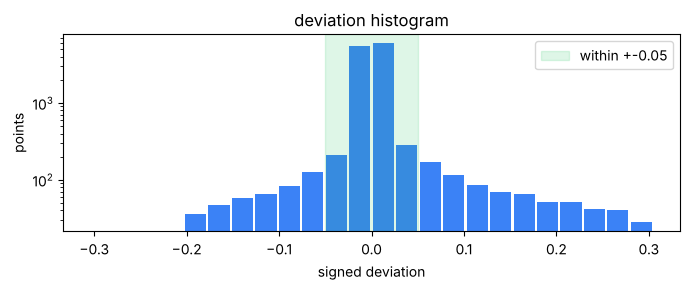

2026-11-09 00:12:53.756 (   0.695s) [    7FB8956D6080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


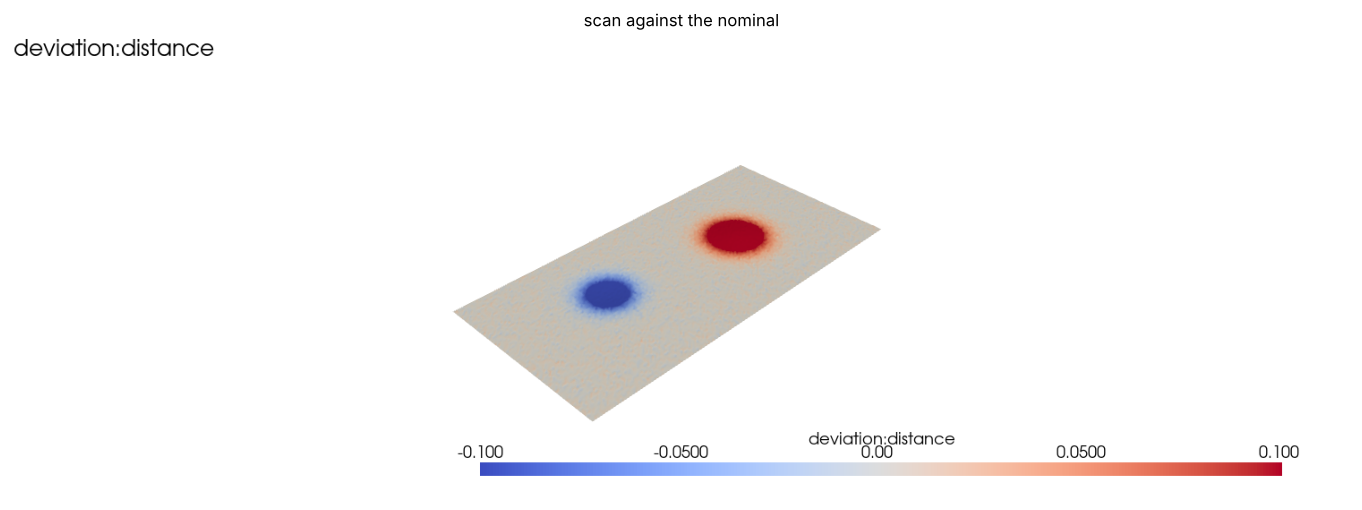

In [4]:
edges = np.array(report['histogram_edges'])
counts = np.array(report['histogram_counts'])
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(0.5 * (edges[:-1] + edges[1:]), counts, width=(edges[1] - edges[0]) * 0.9, color='#3b82f6')
ax.axvspan(-0.05, 0.05, color='#22c55e', alpha=0.15, label='within +-0.05')
ax.set(title='deviation histogram', xlabel='signed deviation', ylabel='points', yscale='log')
ax.legend()
plt.tight_layout()
plt.show()
r = report['suggested_range']
render([(measured, 'deviation:distance', 'deviation:distance')], 'scan against the nominal',
       clim=(-r, r))

## Excess and missing material

`deviation_regions` labels the connected regions beyond the tolerance, each with its area, extreme and mean deviation, a signed volume estimate (the sum of deviation times area), centroid and bounds, and writes them as named cell regions a later `split` or `crop` can isolate.

deviation:excess_0     cells   724  area   45.41  extreme +0.299  volume +6.304  centroid (12.0, 10.0)
deviation:missing_0    cells   419  area   26.25  extreme -0.196  volume -2.830  centroid (28.0, 8.0)


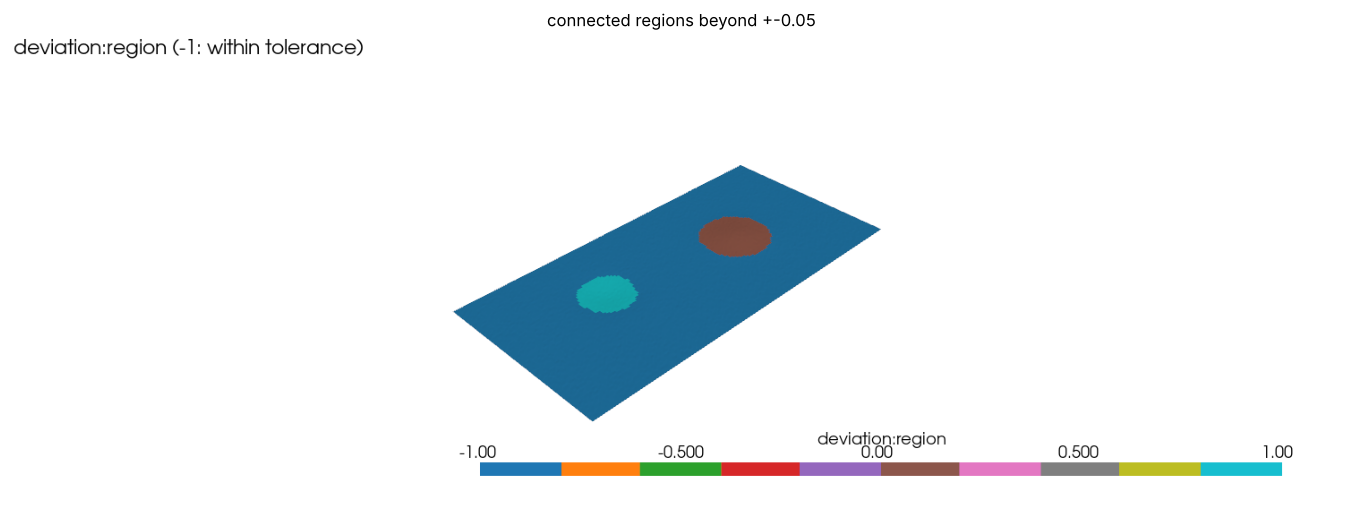

In [5]:
marked, regions = mp.deviation_regions(measured, 0.05, min_area=1.0, return_report=True)
for g in regions['regions']:
    c = g['centroid']
    print(f"{g['name']:22s} cells {g['num_cells']:5d}  area {g['area']:7.2f}  extreme {g['extreme']:+.3f}"
          f"  volume {g['volume']:+.3f}  centroid ({c[0]:.1f}, {c[1]:.1f})")
render([(marked, 'deviation:region', 'deviation:region (-1: within tolerance)')],
       'connected regions beyond +-0.05', cmap='tab10')

## Against a fitted primitive

With a fitted primitive as the reference, the distance is analytic and needs no nominal: here the scan's own least-squares plane, so the map reads its flatness.

In [6]:
plane = mp.fit_primitives(scan, patch_data='', tolerance=0.5)
flat, frep = mp.deviation(scan, plane, patch=0, return_report=True)
print('form error of the top face:', np.ravel(plane.field_data['fit:patch_form_error'])[0])
print('deviation from its plane: min', round(frep['min'], 4), 'max', round(frep['max'], 4))

form error of the top face: 0.49144158145979766
deviation from its plane: min -0.1981 max 0.2934


## Showing the map: colours and exaggeration

`colorize` bakes the map into UInt8 `red`, `green` and `blue` point data through a colormap, here banded at ten fixed steps: PLY writes them as vertex colours, glTF takes them with `color_by="rgb"`. `exaggerate` moves each point along its normal by 20 times its (clamped, smoothed) deviation, for a figure; the measured scan is not touched.

colour range -0.3046 0.3046


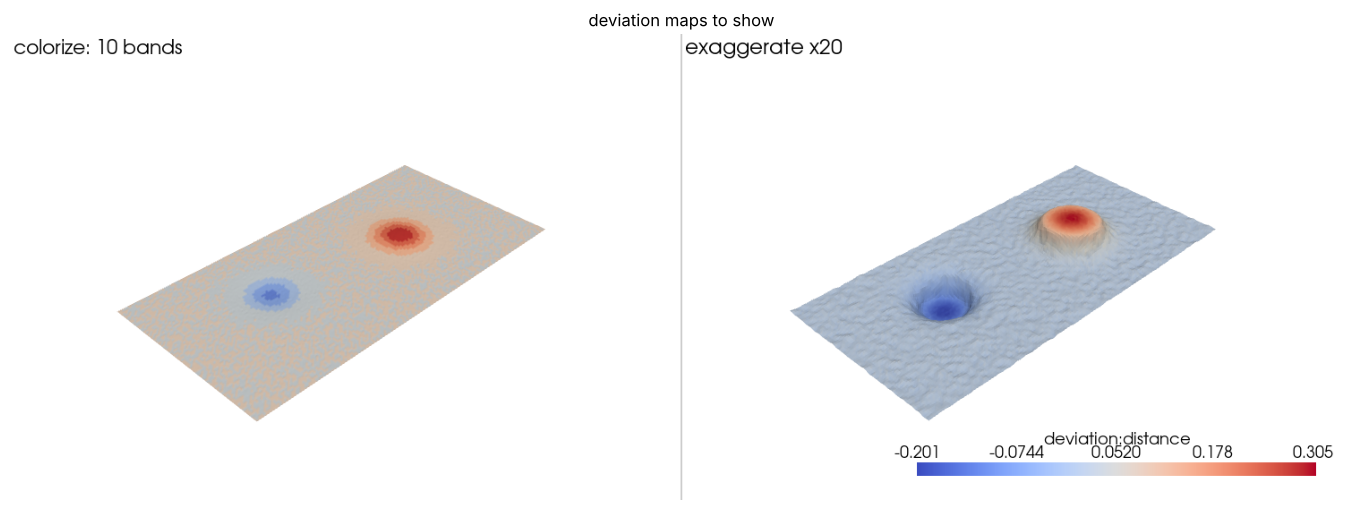

In [7]:
coloured, crep = mp.colorize(measured, 'deviation:distance', cmap='coolwarm', symmetric=True,
                             steps=10, return_report=True)
print('colour range', round(crep['vmin'], 4), round(crep['vmax'], 4))
mp.write(os.path.join(WORK, 'deviation.ply'), coloured)
mp.write(os.path.join(WORK, 'deviation.glb'), coloured, color_by='rgb')
big = mp.exaggerate(measured, scale=20.0)
render([(coloured, None, 'colorize: 10 bands'), (big, 'deviation:distance', 'exaggerate x20')],
       'deviation maps to show', rgb=True)